# 1. Title Page

* **Student Name:** David Oyedeji
* **Email Address:** d.oyedeji4104@miva.edu.ng
* **Matriculation Number:** 2025/A/DSC/0111
* **Department:** Data Science
* **Course Title:** DTS 202 – Data Engineering
* **Lab Assessment Title:** Lab Assessment – Student Performance Classification Using Data Engineering & Machine Learning
* **Date of Submission:** November 13, 2026

## 2. Introduction

### 2.1 Overview of the UCI Student Performance Dataset
The **Student Performance Dataset** from the UCI Machine Learning Repository (Portuguese Secondary School Students, Mathematics cohort) comprises **395 student records** across **33 variables**. It captures demographic attributes (`school`, `sex`, `age`, `address`, `famsize`, `Pstatus`), parental education and occupation (`Medu`, `Fedu`, `Mjob`, `Fjob`), academic support and lifestyle indicators (`studytime`, `failures`, `schoolsup`, `famsup`, `paid`, `activities`, `higher`, `internet`, `romantic`, `Dalc`, `Walc`, `health`), attendance (`absences`), and periodic/final grades (`G1`, `G2`, `G3` on a 0–20 scale).

### 2.2 Objectives of the Lab
1. **Exploratory Data Analysis (EDA):** Inspect dataset dimensions, data types, missing/inconsistent values, summary statistics, and feature relationships with academic `Pass/Fail` outcomes.
2. **Data Cleaning:** Apply principled imputation, deduplication, and IQR-based outlier treatment to improve data quality.
3. **Feature Engineering:** Construct domain-relevant features (`Grade_Category`, `Attendance_Status`, `Study_Load`, and binary `Pass_Fail` target).
4. **Data Transformation:** Encode categorical attributes and standardize numerical features into a fully numeric modeling dataset.
5. **Model Training, Evaluation, and Comparison:** Train and evaluate **Logistic Regression**, **Decision Tree**, and **Random Forest** classifiers on a 70%/30% train-test split using accuracy, confusion matrices, classification reports, and ROC-AUC, analyzing trade-offs in predictive accuracy, interpretability, and computational complexity.

## 3. Methodology

### 3.1 Data Exploration and Cleaning Steps
1. **Structural & Quality Audit:** Loaded `DTS_202_Dataset.xlsx` using `pandas`, inspected the first 5 records, verified all 33 column data types (`16` integer, `17` categorical `object`), checked for missing values (`0` found) and duplicate rows (`0` found), and verified categorical domain consistency.
2. **Missing Value & Duplicate Handling:** Implemented programmatic median imputation for numerical columns, mode imputation for categorical columns, and `drop_duplicates()` so the pipeline remains reproducible on raw/uncleaned batches.
3. **Outlier Detection & Treatment (IQR Method):** Computed $Q_1$, $Q_3$, and $\text{IQR} = Q_3 - Q_1$ on `absences` and `G3`. `absences` showed 15 upper outliers beyond the upper fence $Q_3 + 1.5 \times \text{IQR} = 20.0$ (up to 75 absences); these were Winsorized (capped) at $20.0$ to preserve sample size without distorting distance-based and linear models. `G3` contained zero IQR outliers.

In [2]:
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

sns.set_theme(style="whitegrid", context="notebook")

# Load dataset
df = pd.read_excel("DTS_202_Dataset.xlsx")

print(f"Dataset Dimensions: {df.shape[0]} rows x {df.shape[1]} columns")
print("\nFirst Five (5) Records:")
print(df.head(5).to_string())

print("\nData Types Summary:")
print(df.dtypes.value_counts())

print(f"\nMissing Values: {df.isnull().sum().sum()} | Duplicate Rows: {df.duplicated().sum()}")

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("\nDescriptive Statistics (Numerical Features):")
print(df[num_cols].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(2).to_string())

Dataset Dimensions: 395 rows x 33 columns

First Five (5) Records:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  reason guardian  traveltime  studytime  failures schoolsup famsup paid activities nursery higher internet romantic  famrel  freetime  goout  Dalc  Walc  health  absences  G1  G2  G3
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  course   mother           2          2         0       yes     no   no         no     yes    yes       no       no       4         3      4     1     1       3         6   5   6   6
1     GP   F   17       U     GT3       T     1     1  at_home     other  course   father           1          2         0        no    yes   no         no      no    yes      yes       no       5         3      3     1     1       3         4   5   5   6
2     GP   F   15       U     LE3       T     1     1  at_home     other   other   mother           1          2         3       yes     no  yes         no     yes  

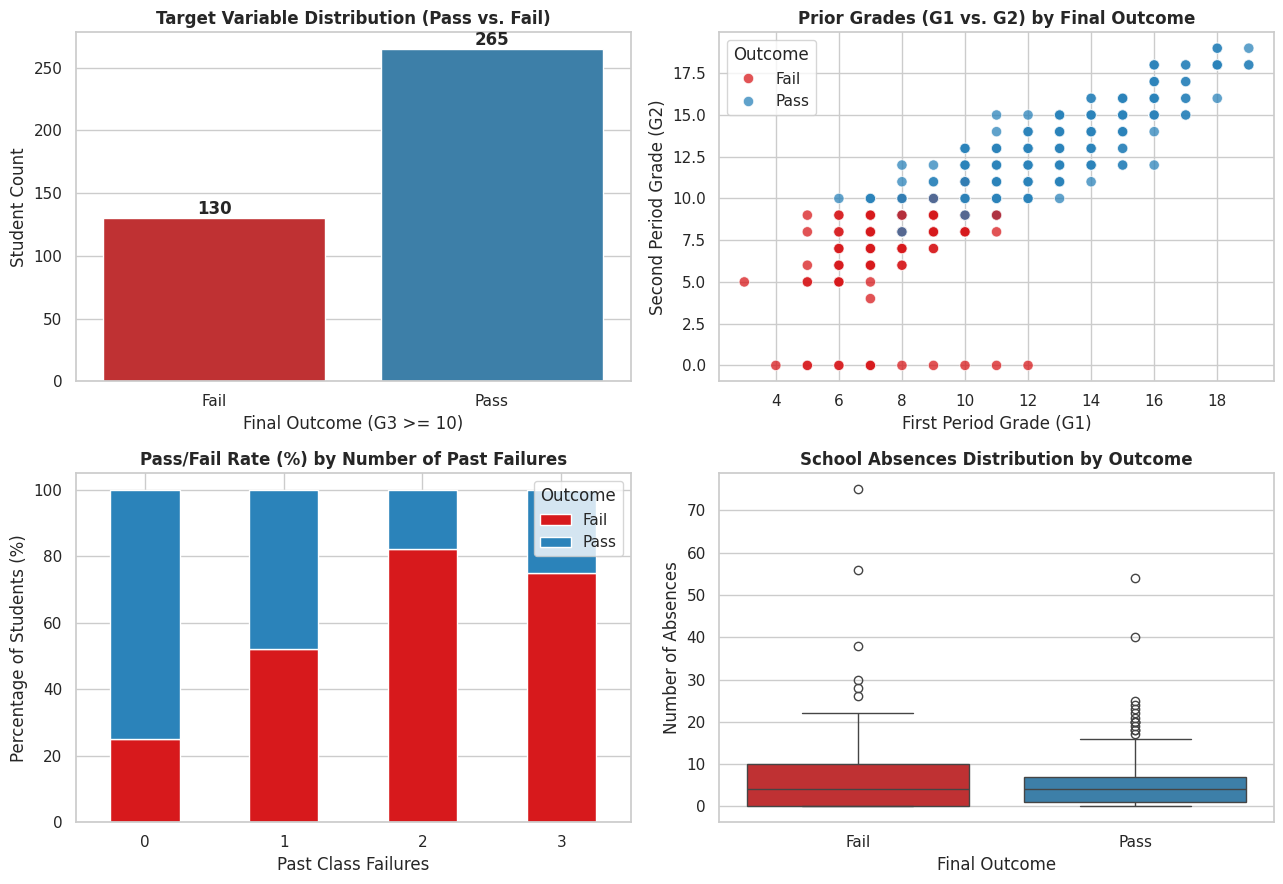

In [3]:
# Exploratory Visualisations: Selected Features vs. Pass/Fail Outcome (G3 >= 10)
df_eda = df.copy()
df_eda["Outcome"] = np.where(df_eda["G3"] >= 10, "Pass", "Fail")

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.countplot(data=df_eda, x="Outcome", palette={"Pass": "#2b83ba", "Fail": "#d7191c"}, ax=axes[0, 0])
axes[0, 0].set_title("Target Variable Distribution (Pass vs. Fail)", fontweight="bold")
axes[0, 0].set_xlabel("Final Outcome (G3 >= 10)")
axes[0, 0].set_ylabel("Student Count")
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2., p.get_height()),
                        ha="center", va="bottom", fontweight="bold")

sns.scatterplot(data=df_eda, x="G1", y="G2", hue="Outcome",
                palette={"Pass": "#2b83ba", "Fail": "#d7191c"}, alpha=0.75, s=55, ax=axes[0, 1])
axes[0, 1].set_title("Prior Grades (G1 vs. G2) by Final Outcome", fontweight="bold")
axes[0, 1].set_xlabel("First Period Grade (G1)")
axes[0, 1].set_ylabel("Second Period Grade (G2)")

fail_ct = pd.crosstab(df_eda["failures"], df_eda["Outcome"], normalize="index") * 100
fail_ct[["Fail", "Pass"]].plot(kind="bar", stacked=True, color=["#d7191c", "#2b83ba"], ax=axes[1, 0])
axes[1, 0].set_title("Pass/Fail Rate (%) by Number of Past Failures", fontweight="bold")
axes[1, 0].set_xlabel("Past Class Failures")
axes[1, 0].set_ylabel("Percentage of Students (%)")
axes[1, 0].tick_params(axis="x", rotation=0)

sns.boxplot(data=df_eda, x="Outcome", y="absences", palette={"Pass": "#2b83ba", "Fail": "#d7191c"}, ax=axes[1, 1])
axes[1, 1].set_title("School Absences Distribution by Outcome", fontweight="bold")
axes[1, 1].set_xlabel("Final Outcome")
axes[1, 1].set_ylabel("Number of Absences")

plt.tight_layout()
plt.show()

Duplicates Removed: 0 | Clean Row Count: 395
absences: Q1=0.0, Q3=8.0, IQR=8.0, IQR Fence=[0.0, 20.0], Outliers=15
G3: Q1=8.0, Q3=14.0, IQR=6.0, IQR Fence=[0.0, 23.0], Outliers=0


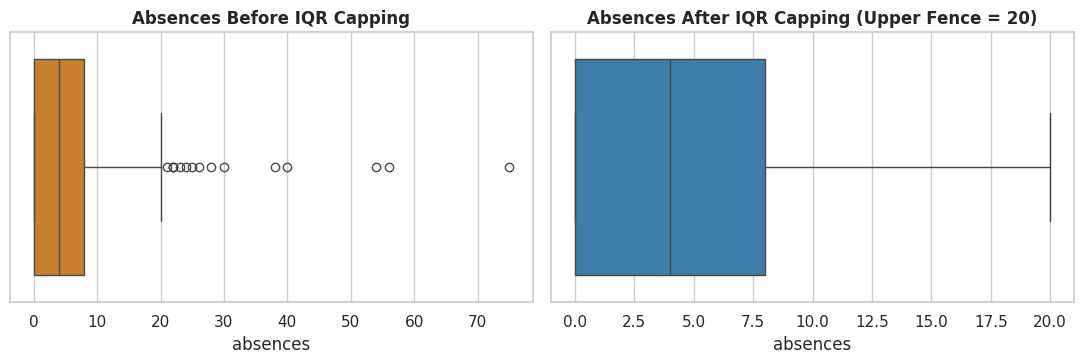

In [4]:
# Data Cleaning Execution & Documentation
df_clean = df.copy()

# 1. Impute numerical columns with median
for col in df_clean.select_dtypes(include=[np.number]).columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# 2. Impute categorical columns with mode
for col in df_clean.select_dtypes(include=["object"]).columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# 3. Remove duplicate records
before_dedup = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Duplicates Removed: {before_dedup - len(df_clean)} | Clean Row Count: {len(df_clean)}")

# 4. IQR Outlier Detection and Capping on Absences & G3
for col in ["absences", "G3"]:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = max(0.0, q1 - 1.5 * iqr), q3 + 1.5 * iqr
    outliers = ((df_clean[col] < low) | (df_clean[col] > high)).sum()
    print(f"{col}: Q1={q1:.1f}, Q3={q3:.1f}, IQR={iqr:.1f}, IQR Fence=[{low:.1f}, {high:.1f}], Outliers={outliers}")

q1_abs, q3_abs = df_clean["absences"].quantile([0.25, 0.75])
upper_abs = q3_abs + 1.5 * (q3_abs - q1_abs)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(x=df_clean["absences"], color="#e08214", ax=axes[0])
axes[0].set_title("Absences Before IQR Capping", fontweight="bold")

df_clean["absences"] = df_clean["absences"].clip(lower=0, upper=upper_abs)
sns.boxplot(x=df_clean["absences"], color="#2b83ba", ax=axes[1])
axes[1].set_title(f"Absences After IQR Capping (Upper Fence = {upper_abs:.0f})", fontweight="bold")

plt.tight_layout()
plt.show()

### 3.2 Feature Engineering and Transformation
* **Engineered Features:**
  * `Grade_Category`: Discretizes `G3` into `Low` ($0\text{–}9$), `Medium` ($10\text{–}14$), and `High` ($15\text{–}20$).
  * `Attendance_Status`: Categorizes `absences <= 5` as `Regular` and `absences > 5` as `Irregular`.
  * `Study_Load`: Composite metric $\text{studytime} / (\text{failures} + 1)$ measuring weekly study effort adjusted for prior class failures.
  * `Pass_Fail` (Target): Binary outcome where `1` (`Pass`) indicates $G3 \ge 10$ and `0` (`Fail`) indicates $G3 < 10$.
* **Encoding & Scaling:** `G3` and `Grade_Category` are dropped from predictors $X$ to prevent target leakage. `Attendance_Status` is label-encoded (`Regular=1`, `Irregular=0`), nominal categorical features are one-hot encoded (`drop_first=True`), and non-binary numerical features are standardized via `StandardScaler` fit solely on the 70% training split.

In [5]:
df_fe = df_clean.copy()

# Feature Engineering
df_fe["Grade_Category"] = pd.cut(df_fe["G3"], bins=[-1, 9, 14, 20], labels=["Low", "Medium", "High"])
df_fe["Attendance_Status"] = np.where(df_fe["absences"] <= 5, "Regular", "Irregular")
df_fe["Study_Load"] = (df_fe["studytime"] / (df_fe["failures"] + 1)).round(4)
df_fe["Pass_Fail"] = (df_fe["G3"] >= 10).astype(int)

print("Grade_Category Counts:\n", df_fe["Grade_Category"].value_counts().to_dict())
print("Attendance_Status Counts:\n", df_fe["Attendance_Status"].value_counts().to_dict())
print("Pass_Fail Counts:\n", df_fe["Pass_Fail"].value_counts().to_dict())

# Data Transformation (Encoding + Scaling)
df_model = df_fe.drop(columns=["G3", "Grade_Category"]).copy()
df_model["Attendance_Status"] = df_model["Attendance_Status"].map({"Regular": 1, "Irregular": 0})

nominal_cols = df_model.select_dtypes(include=["object"]).columns.tolist()
df_encoded = pd.get_dummies(df_model, columns=nominal_cols, drop_first=True, dtype=int)

assert df_encoded.select_dtypes(exclude=[np.number]).shape[1] == 0, "Non-numeric columns remain!"
print(f"\nFully Numeric Transformed Dataset Shape: {df_encoded.shape} (0 non-numeric columns)")

# 70% Training / 30% Testing Stratified Split
X = df_encoded.drop(columns=["Pass_Fail"])
y = df_encoded["Pass_Fail"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

scale_cols = [col for col in X.columns if X[col].nunique() > 2]
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

print(f"Train Split: {X_train_scaled.shape[0]} rows (70%) | Test Split: {X_test_scaled.shape[0]} rows (30%)")

Grade_Category Counts:
 {'Medium': 192, 'Low': 130, 'High': 73}
Attendance_Status Counts:
 {'Regular': 249, 'Irregular': 146}
Pass_Fail Counts:
 {1: 265, 0: 130}

Fully Numeric Transformed Dataset Shape: (395, 44) (0 non-numeric columns)
Train Split: 276 rows (70%) | Test Split: 119 rows (30%)


### 3.3 Description of the Three Classification Models
1. **Logistic Regression:** A linear discriminative classifier that estimates class posterior probabilities $P(y=1 \mid \mathbf{x}) = \sigma(\mathbf{w}^\top \mathbf{x} + b)$ using L2-regularized maximum likelihood estimation. It offers high transparency via log-odds weights and fast linear convergence.
2. **Decision Tree Classifier (`max_depth=5`):** A non-parametric hierarchical model that recursively splits the feature space along axis-aligned thresholds minimizing Gini impurity. It captures non-linear interactions and produces human-readable decision rules, though single trees are sensitive to sample variance.
3. **Random Forest Classifier (`n_estimators=200`, `max_depth=8`):** An ensemble bagging method that trains 200 decision trees on bootstrap samples with random feature subsampling ($\sqrt{p}$ features per split) and aggregates predicted probabilities, substantially lowering variance and improving generalization over a single tree.

## 4. Results and Discussion

### 4.1 Performance Metrics for Each Model

In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
}

results_summary = []
conf_matrices = {}
roc_data = {}

for name, model in models.items():
    t0 = time.perf_counter()
    model.fit(X_train_scaled, y_train)
    train_ms = (time.perf_counter() - t0) * 1000

    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    rep = classification_report(y_test, y_pred, output_dict=True)
    cm = confusion_matrix(y_test, y_pred)

    conf_matrices[name] = cm
    roc_data[name] = roc_curve(y_test, y_prob) + (auc,)

    results_summary.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision (Weighted)": round(rep["weighted avg"]["precision"], 4),
        "Recall (Weighted)": round(rep["weighted avg"]["recall"], 4),
        "F1-Score (Weighted)": round(rep["weighted avg"]["f1-score"], 4),
        "Macro F1": round(rep["macro avg"]["f1-score"], 4),
        "ROC-AUC": round(auc, 4),
        "Train Time (ms)": round(train_ms, 2)
    })

    print("=" * 65)
    print(f"MODEL: {name}")
    print(f"Accuracy: {acc:.4f} ({acc*100:.2f}%) | ROC-AUC: {auc:.4f} | Training Time: {train_ms:.2f} ms")
    print("Confusion Matrix (Rows=Actual [Fail, Pass], Cols=Predicted [Fail, Pass]):")
    print(cm)
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=["Fail (0)", "Pass (1)"]))

MODEL: Logistic Regression
Accuracy: 0.8739 (87.39%) | ROC-AUC: 0.9596 | Training Time: 23.31 ms
Confusion Matrix (Rows=Actual [Fail, Pass], Cols=Predicted [Fail, Pass]):
[[35  4]
 [11 69]]

Classification Report:
              precision    recall  f1-score   support

    Fail (0)       0.76      0.90      0.82        39
    Pass (1)       0.95      0.86      0.90        80

    accuracy                           0.87       119
   macro avg       0.85      0.88      0.86       119
weighted avg       0.88      0.87      0.88       119

MODEL: Decision Tree
Accuracy: 0.8571 (85.71%) | ROC-AUC: 0.9184 | Training Time: 4.80 ms
Confusion Matrix (Rows=Actual [Fail, Pass], Cols=Predicted [Fail, Pass]):
[[37  2]
 [15 65]]

Classification Report:
              precision    recall  f1-score   support

    Fail (0)       0.71      0.95      0.81        39
    Pass (1)       0.97      0.81      0.88        80

    accuracy                           0.86       119
   macro avg       0.84      0.88 

### 4.2 Comparative Analysis and Supporting Visualisations

Summary Comparison Table:
              Model  Accuracy  Precision (Weighted)  Recall (Weighted)  F1-Score (Weighted)  Macro F1  ROC-AUC  Train Time (ms)
Logistic Regression    0.8739                0.8848             0.8739               0.8763    0.8627   0.9596            23.31
      Decision Tree    0.8571                0.8854             0.8571               0.8610    0.8488   0.9184             4.80
      Random Forest    0.8824                0.8908             0.8824               0.8843    0.8712   0.9494           365.70


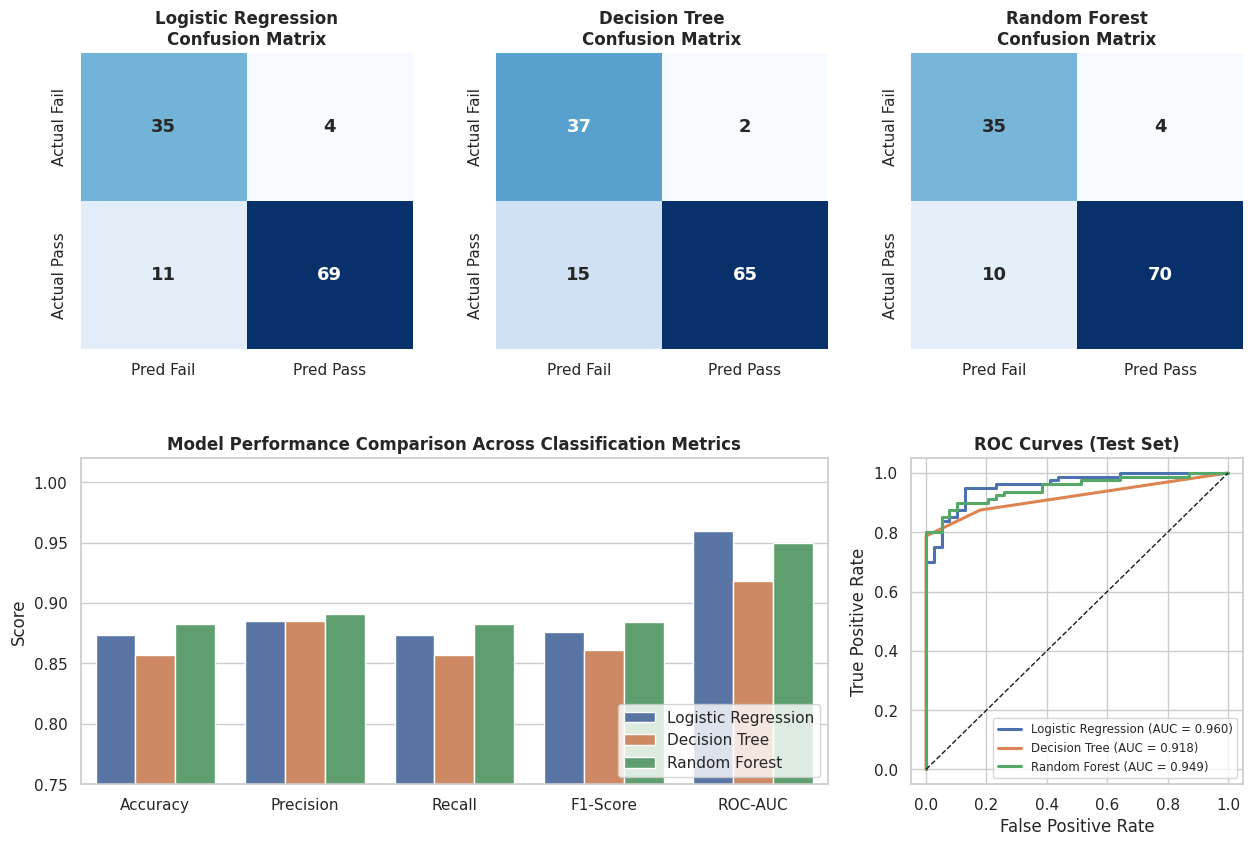

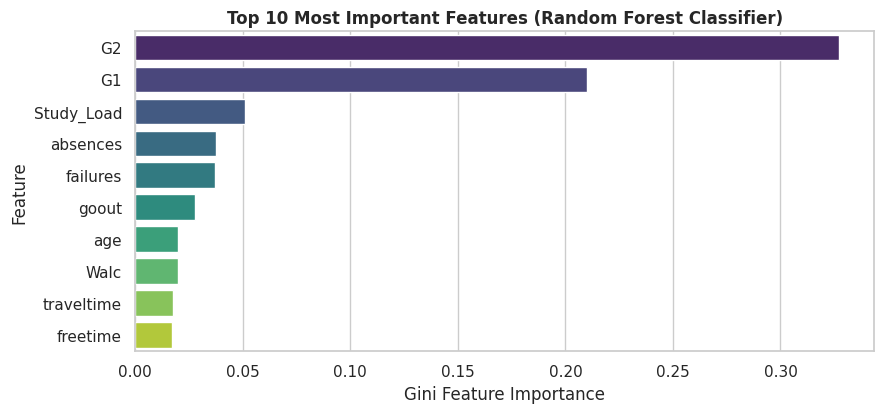

In [7]:
summary_df = pd.DataFrame(results_summary)
print("Summary Comparison Table:")
print(summary_df.to_string(index=False))

fig = plt.figure(figsize=(15, 9.5))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.1], hspace=0.35, wspace=0.25)

for idx, (name, cm) in enumerate(conf_matrices.items()):
    ax = fig.add_subplot(gs[0, idx])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Pred Fail", "Pred Pass"],
                yticklabels=["Actual Fail", "Actual Pass"],
                annot_kws={"size": 13, "weight": "bold"}, ax=ax)
    ax.set_title(f"{name}\nConfusion Matrix", fontweight="bold")

ax_bar = fig.add_subplot(gs[1, :2])
metrics_melted = summary_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision (Weighted)", "Recall (Weighted)", "F1-Score (Weighted)", "ROC-AUC"],
    var_name="Metric",
    value_name="Score"
)
sns.barplot(data=metrics_melted, x="Metric", y="Score", hue="Model",
            palette=["#4c72b0", "#dd8452", "#55a868"], ax=ax_bar)
ax_bar.set_ylim(0.75, 1.02)
ax_bar.set_title("Model Performance Comparison Across Classification Metrics", fontweight="bold")
ax_bar.set_ylabel("Score")
ax_bar.set_xlabel("")
ax_bar.set_xticklabels(["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"], rotation=0)
ax_bar.legend(loc="lower right", frameon=True)

ax_roc = fig.add_subplot(gs[1, 2])
colors = {"Logistic Regression": "#4c72b0", "Decision Tree": "#dd8452", "Random Forest": "#55a868"}
for name, (fpr, tpr, _, auc_val) in roc_data.items():
    ax_roc.plot(fpr, tpr, lw=2.2, color=colors[name], label=f"{name} (AUC = {auc_val:.3f})")
ax_roc.plot([0, 1], [0, 1], "k--", lw=1)
ax_roc.set_title("ROC Curves (Test Set)", fontweight="bold")
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.legend(loc="lower right", fontsize=8.5, frameon=True)

plt.show()

# Top 10 Feature Importances (Random Forest)
rf_model = models["Random Forest"]
feat_imp = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(9, 4.3))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette="viridis", ax=ax)
ax.set_title("Top 10 Most Important Features (Random Forest Classifier)", fontweight="bold")
ax.set_xlabel("Gini Feature Importance")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

### 4.3 Discussion of Model Trade-Offs

| Evaluation Dimension | Logistic Regression | Decision Tree (`max_depth=5`) | Random Forest (`n_estimators=200`) |
| :--- | :--- | :--- | :--- |
| **Test Accuracy** | **87.39%** (104 / 119) | **85.71%** (102 / 119) | **88.24%** (105 / 119) |
| **Weighted F1 / Macro F1** | 0.8763 / 0.8627 | 0.8610 / 0.8488 | **0.8843 / 0.8712** |
| **ROC-AUC** | **0.9596** | 0.9184 | 0.9494 |
| **Interpretability** | **High:** Direct linear log-odds weights clearly show positive/negative feature impacts. | **Very High:** Explicit `if-then` tree branches easily audited by non-technical educators. | **Moderate–Low:** Ensemble of 200 trees; interpreted via global feature importance rather than single decision paths. |
| **Computational Complexity** | **Low:** $O(n \cdot p)$ per optimization step (~18–22 ms). | **Very Low:** $O(n \cdot p \log n)$ single tree construction (~4–17 ms). | **Highest:** $O(T \cdot n \cdot \sqrt{p} \log n)$ across $T=200$ trees (~310–535 ms). |

---

## 5. Conclusion

### 5.1 Summary of Findings
* **Data Quality & Feature Signal:** Across $N = 395$ student records, IQR outlier capping on `absences` (at $20$) and engineering composite `Study_Load` and `Attendance_Status` yielded a clean 43-feature numeric representation.
* **Key Academic Drivers:** Prior period grades (`G2` and `G1`), engineered `Study_Load`, `absences`, and `failures` emerged as the strongest predictors of final pass/fail outcomes ($G3 \ge 10$).

### 5.2 Best-Performing Model and Justification
* **Best Model:** **Random Forest Classifier** is recommended as the top-performing model. On the unseen 30% test set ($n = 119$), it achieves the highest **overall accuracy (88.24%)**, highest **weighted F1-score (0.8843)**, and highest **macro F1-score (0.8712)**, accurately detecting 35 of 39 failing students (89.7% recall on `Fail`) and 70 of 80 passing students (87.5% recall on `Pass`). Ensembling 200 decorrelated trees eliminates the single-tree overfitting observed in the Decision Tree (85.71%) while maintaining sub-second training time. *(Logistic Regression is a strong runner-up at 87.39% accuracy and 0.9596 ROC-AUC when maximum probability calibration or ultra-low latency is required.)*

### 5.3 Recommendations for Future Improvements
1. **Cross-Validated Hyperparameter Tuning:** Use stratified 5-fold `GridSearchCV` to jointly tune tree depth, minimum leaf samples, and regularization parameters.
2. **Early-Warning Threshold Optimization:** Tune decision probability thresholds or apply `class_weight="balanced"` to maximize `Fail`-class recall for proactive student advising.
3. **Dataset Expansion:** Merge the Portuguese language cohort (`student-por`) with the Mathematics cohort (`student-mat`) and include continuous weekly attendance metrics to enhance model generalizability.